<a href="https://colab.research.google.com/github/ssamirbaba39/python-workshop-basics/blob/main/qouk%20sort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running Algorithms...
Benchmark Finished!


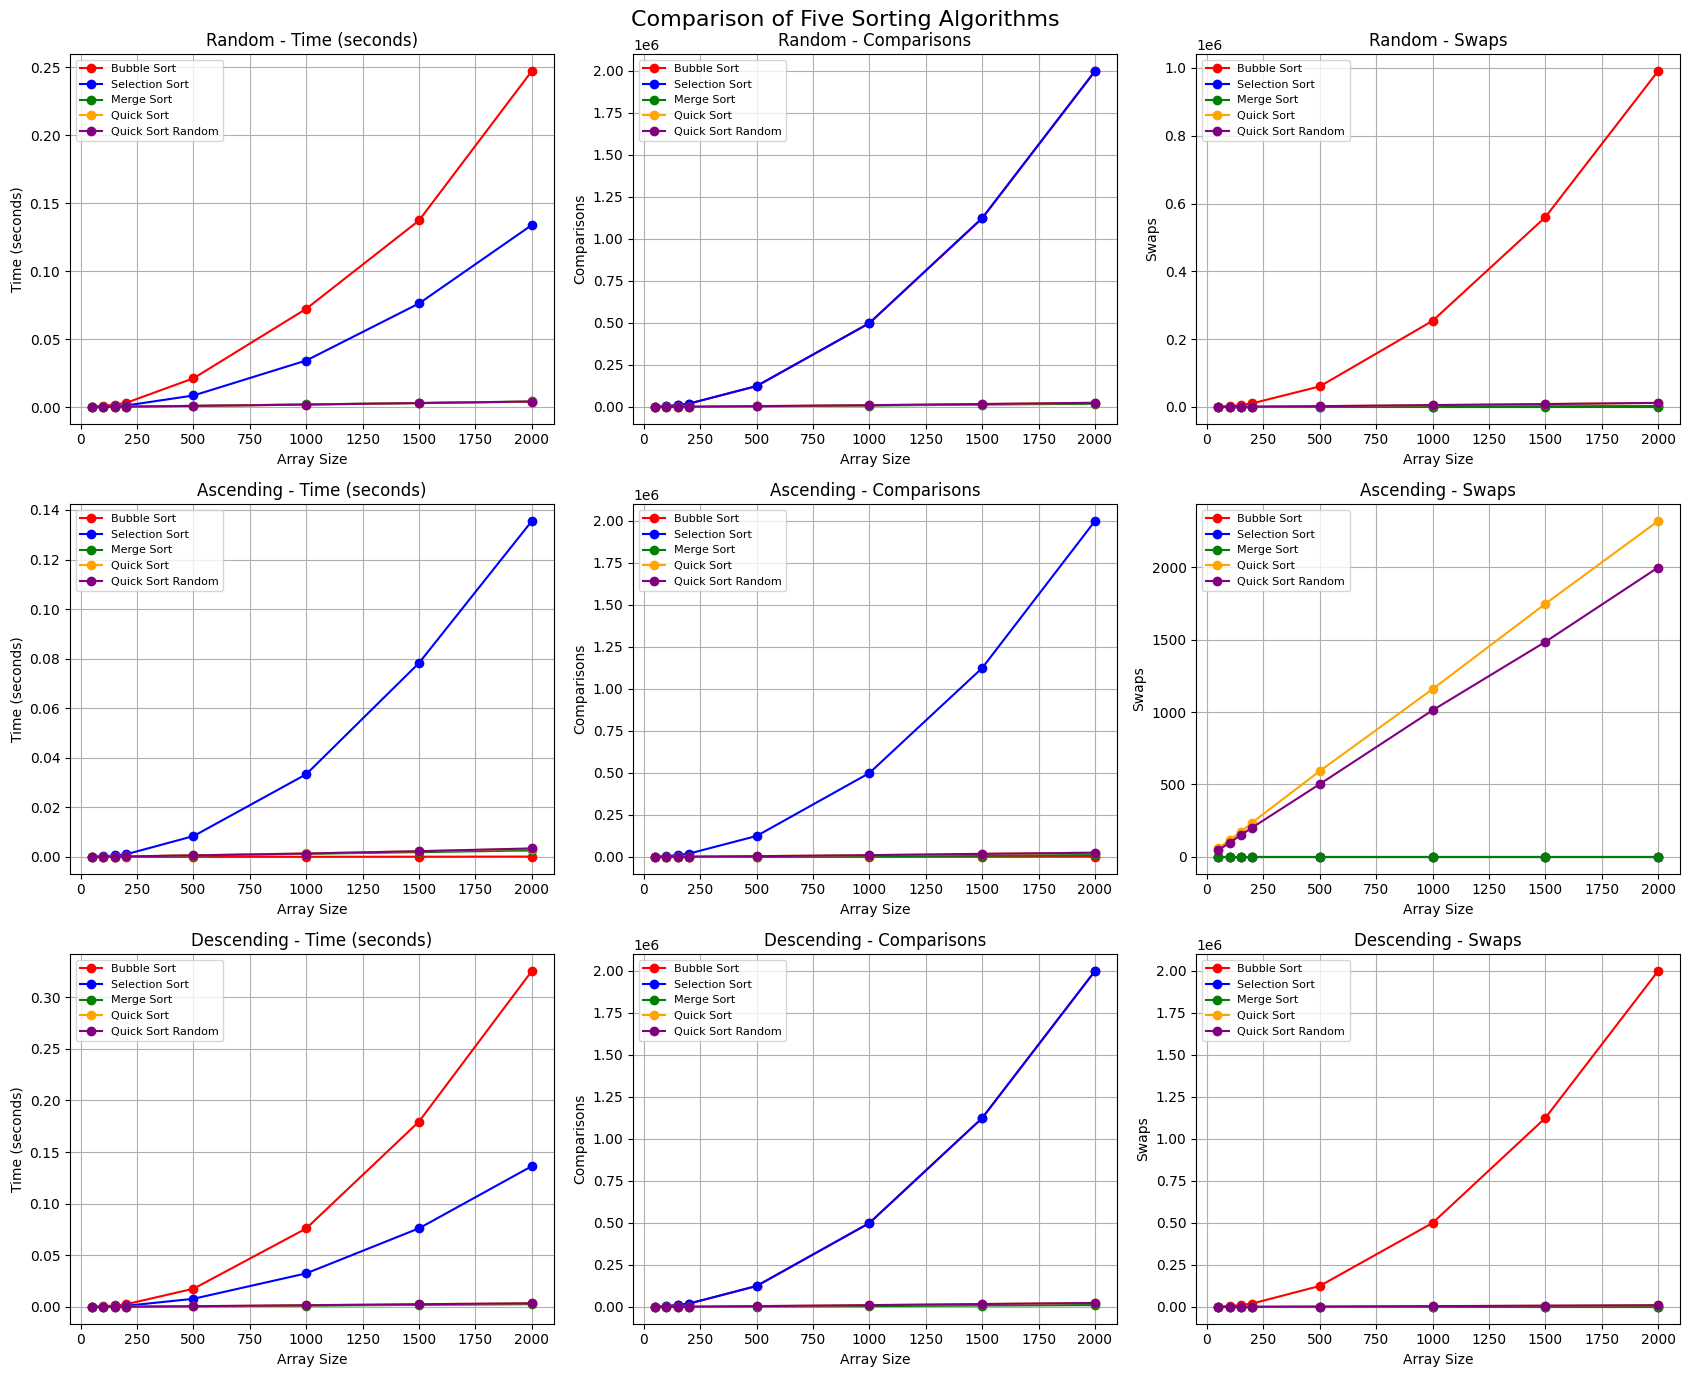

In [18]:
import random
import time
import matplotlib.pyplot as plt


# ---------- Data Generation ----------
def generate(n, kind):
    if kind == "rand":
        return [random.randint(0, n) for _ in range(n)]
    elif kind == "asc":
        return list(range(n))
    elif kind == "desc":
        return list(range(n, 0, -1))
    raise ValueError("Invalid kind")


# ---------- Bubble Sort ----------
def bubbleSort(lst):
    comp = swap = 0
    n = len(lst)

    for i in range(n - 1):
        swapped = False

        for j in range(n - 1 - i):
            comp += 1

            if lst[j] > lst[j + 1]:
                lst[j], lst[j + 1] = lst[j + 1], lst[j]
                swap += 1
                swapped = True

        if not swapped:
            break

    return comp, swap


# ---------- Selection Sort ----------
def selectionSort(lst):
    comp = swap = 0
    n = len(lst)

    for i in range(n):
        m = i

        for j in range(i + 1, n):
            comp += 1

            if lst[j] < lst[m]:
                m = j

        if m != i:
            lst[i], lst[m] = lst[m], lst[i]
            swap += 1

    return comp, swap


# ---------- Merge Sort ----------
def mergeSort(lst):
    comp = 0

    def merge(arr):
        nonlocal comp

        if len(arr) <= 1:
            return arr

        mid = len(arr) // 2

        left = merge(arr[:mid])
        right = merge(arr[mid:])

        result = []
        i = j = 0

        while i < len(left) and j < len(right):
            comp += 1

            if left[i] <= right[j]:
                result.append(left[i])
                i += 1
            else:
                result.append(right[j])
                j += 1

        result.extend(left[i:])
        result.extend(right[j:])

        return result

    lst[:] = merge(lst)
    return comp, 0


# ---------- Quick Sort Normal ----------

def quickSort(lst):
    comp = 0
    swap = 0

    def quick(arr, low, high):
        nonlocal comp, swap

        if low < high:

            # اختيار Pivot عشوائي
            random_index = random.randint(low, high)

            arr[random_index], arr[high] = arr[high], arr[random_index]
            swap += 1

            pivot = arr[high]
            i = low - 1

            for j in range(low, high):
                comp += 1

                if arr[j] <= pivot:
                    i += 1

                    if i != j:
                        arr[i], arr[j] = arr[j], arr[i]
                        swap += 1

            if i + 1 != high:
                arr[i + 1], arr[high] = arr[high], arr[i + 1]
                swap += 1

            pi = i + 1

            quick(arr, low, pi - 1)
            quick(arr, pi + 1, high)

    quick(lst, 0, len(lst) - 1)

    return comp, swap

# ---------- Quick Sort Random Pivot ----------
def quickSortRandom(lst):
    comp = 0
    swap = 0

    def quick(arr, low, high):
        nonlocal comp, swap

        if low < high:

            # Random Pivot
            random_index = random.randint(low, high)

            if random_index != high:
                arr[random_index], arr[high] = arr[high], arr[random_index]
                swap += 1

            pivot = arr[high]
            i = low - 1

            for j in range(low, high):
                comp += 1

                if arr[j] <= pivot:
                    i += 1

                    if i != j:
                        arr[i], arr[j] = arr[j], arr[i]
                        swap += 1

            if i + 1 != high:
                arr[i + 1], arr[high] = arr[high], arr[i + 1]
                swap += 1

            pi = i + 1

            quick(arr, low, pi - 1)
            quick(arr, pi + 1, high)

    quick(lst, 0, len(lst) - 1)
    return comp, swap


# ---------- Benchmark ----------

# ---------- Benchmark ----------
SIZES = [50, 100, 150, 200, 500, 1000, 1500, 2000]

KINDS = ["rand", "asc", "desc"]


def runTest(func, repeats=3):

    results = {
        k: {"size": [], "time": [], "comp": [], "swap": []}
        for k in KINDS
    }

    for kind in KINDS:
        for size in SIZES:

            times = []
            comps = []
            swaps = []

            for _ in range(repeats):

                data = generate(size, kind)

                start = time.perf_counter()
                comp, swap = func(data)
                end = time.perf_counter()

                times.append(end - start)
                comps.append(comp)
                swaps.append(swap)

            r = results[kind]

            r["size"].append(size)
            r["time"].append(sum(times) / repeats)
            r["comp"].append(sum(comps) / repeats)
            r["swap"].append(sum(swaps) / repeats)

    return results

# ---------- Run Algorithms ----------
print("Running Algorithms...")

bubble = runTest(bubbleSort)
selection = runTest(selectionSort)
merge = runTest(mergeSort)
quick = runTest(quickSort)
quick_random = runTest(quickSortRandom)

print("Benchmark Finished!")


# ---------- Algorithms List ----------
algorithms = [
    (bubble, "Bubble Sort", "red"),
    (selection, "Selection Sort", "blue"),
    (merge, "Merge Sort", "green"),
    (quick, "Quick Sort", "orange"),
    (quick_random, "Quick Sort Random", "purple")
]


# ---------- Scenarios ----------
scenarios = [
    ("rand", "Random"),
    ("asc", "Ascending"),
    ("desc", "Descending")
]


# ---------- Metrics ----------
metrics = [
    ("time", "Time (seconds)"),
    ("comp", "Comparisons"),
    ("swap", "Swaps")
]


# ---------- 3x3 Plots ----------
fig, axes = plt.subplots(3, 3, figsize=(17, 14))

fig.suptitle(
    "Comparison of Five Sorting Algorithms",
    fontsize=16
)

for i, (kind, scenario) in enumerate(scenarios):

    x = bubble[kind]["size"]

    for j, (metric, ylabel) in enumerate(metrics):

        for results, name, color in algorithms:

            axes[i, j].plot(
                x,
                results[kind][metric],
                color=color,
                label=name,
                marker="o"
            )

        axes[i, j].set_title(scenario + " - " + ylabel)
        axes[i, j].set_xlabel("Array Size")
        axes[i, j].set_ylabel(ylabel)
        axes[i, j].legend(fontsize=8)
        axes[i, j].grid(True)

fig.tight_layout()
plt.show()